# Расчёт цикла двухвального одноконтурного ТВД мощностью 150 л.с.
**Схема:** вход → компрессор → камера сгорания → турбина компрессора → свободная силовая турбина → сопло.

- ТВД150 МКБ «Гранит»
- Honeywell TPE331 

## 1. Импорт библиотек, исходные данные

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Мощность двигателя — 150 л.с. ПОСЛЕ редуктора (на валу винта).
# Мощность силовой турбины находится делением на eta_m_pt * eta_red (см. раздел 9).
power_hp = 150.0
HP_TO_KW = 0.73549875
power_kw = power_hp * HP_TO_KW

# Наружные условия
T_a = 288.0          # K
p_a = 101.3          # кПа
velocity = 0.0       # м/с

# Температура газа перед турбиной (турбины неохлаждаемые)
T_g = 1250.0         # K

# КПД и потери
eta_k_poly = 0.86    # п кпд цбк по методичке 0.85..0.87
eta_gg_poly = 0.90   # п кпд газогенератора
eta_pt_poly = 0.90   # п кпд силовой турбины

sigma_in = 0.985
sigma_burn = 0.965
eta_burn = 0.98

eta_m_gg = 0.99
eta_m_pt = 0.99

# КПД редуктора:
eta_red = 0.98

# Отборы воздуха
g_leak = 0.005
g_cool = 0.0         # турбины без охлаждения

# Топливо и газовые постоянные
Q_lhv = 43000.0      # кДж/кг
l0 = 14.61
T_ref = 288.0        # K
R_air = 0.287        # кДж/(кг К)
R_gas = 0.288        # кДж/(кг К)

# Сопло и выход из свободной турбины
pi_nozzle_static = 1.04
c_pt_exit = 250.0    # м/с
phi_nozzle = 0.95
beta_prop = 15.0     # Н/кВт
eta_prop = 0.82

# Настройки вариантного расчёта
pi_k_selected = 6.0        # πк* задано преподавателем (одноступенчатый ЦБК)
n_variants = 801

KCAL_TO_KJ = 4.187

N_pt_kw = power_kw / (eta_m_pt * eta_red)
print(f"Мощность на валу винта (после редуктора): {power_hp:.0f} л.с. = {power_kw:.3f} кВт")
print(f"Мощность силовой турбины: {N_pt_kw:.3f} кВт = {N_pt_kw/HP_TO_KW:.1f} л.с.")

Мощность на валу винта (после редуктора): 150 л.с. = 110.325 кВт
Мощность силовой турбины: 113.713 кВт = 154.6 л.с.


## 2. Теплофизические свойства

Формулы теплоёмкостей взяты из приложения 6 методички. Для воздуха используется предел alpha → infty

In [2]:
def cp_i(T, alpha=np.inf):
    if np.isinf(alpha):
        a = 0.0
    else:
        a = 1.0 / alpha

    if T < 750.0:
        value = ((0.0174*a + 0.2407)
                 + (0.0093*a + 0.0193)*(2.5e-3*T - 0.875)
                 + (2.0e-3 - 1.056e-3*a/(1.0 - 0.2*a))
                 * (2.5e-5*T*T - 0.0275*T + 6.5625))
    else:
        value = ((0.0267*a + 0.26)
                 + (0.0133*a + 0.032)*(1.176e-3*T - 0.88235)
                 - (0.374e-2 + 0.94e-2*a*a/(1.0 + 10*a*a))
                 * (5.5556e-6*T*T - 1.3056e-2*T + 6.67))

    return KCAL_TO_KJ * value


def cp_m(T, alpha=np.inf):
    a = 0.0 if np.isinf(alpha) else 1.0 / alpha

    if T < 700.0:
        value = (2.25*a + 1.2)/1e5*(T - 70.0) + 0.236
    else:
        value = (1.25*a + 2.2)/1e5*(T + 450.0) + 0.218

    return KCAL_TO_KJ * value


def h(T, alpha=np.inf):
    return cp_m(T, alpha) * T


def dh(T, alpha):
    return h(T, alpha) - h(T_ref, alpha)


def process_properties(T1, T2, alpha, R):
    T_mean = (T1 + T2) / 2
    cp = cp_i(T_mean, alpha)
    k = cp / (cp - R)
    return cp, k


def bisect(fun, left, right, n=80):
    f_left = fun(left)

    for _ in range(n):
        middle = (left + right) / 2
        f_middle = fun(middle)

        if f_left * f_middle <= 0:
            right = middle
        else:
            left = middle
            f_left = f_middle

    return (left + right) / 2

## 3. Входное устройство

In [3]:
def inlet():
    def equation(T2):
        cp, k = process_properties(T_a, T2, np.inf, R_air)
        return T2 - T_a - velocity**2/(2000*cp)

    T2 = bisect(equation, T_a, T_a + velocity**2/1000 + 1)
    cp, k = process_properties(T_a, T2, np.inf, R_air)

    M = velocity / math.sqrt(1000*k*R_air*T_a)
    pi_v = (T2/T_a)**(k/(k-1))
    p2 = p_a * pi_v * sigma_in

    return {
        'T2': T2,
        'p2': p2,
        'pi_v': pi_v,
        'M_flight': M,
        'cp_in': cp,
        'k_in': k
    }

## 4. Компрессор

In [4]:
def compressor(pi_k, inp):
    T2 = inp['T2']

    def equation(T3):
        cp, k = process_properties(T2, T3, np.inf, R_air)
        return T3 - T2*pi_k**((k-1)/(k*eta_k_poly))

    T3 = bisect(equation, T2, T_g)
    cp, k = process_properties(T2, T3, np.inf, R_air)

    x = (k-1)/k * math.log(pi_k)
    eta_k = math.expm1(x) / math.expm1(x/eta_k_poly)

    p3 = inp['p2'] * pi_k
    L_k = cp * (T3 - T2)

    return {
        'T3': T3,
        'p3': p3,
        'L_k': L_k,
        'cp_k': cp,
        'k_k': k,
        'eta_k': eta_k
    }

## 5. Камера сгорания

In [5]:
def combustor(comp):
    denominator = (Q_lhv*eta_burn
                   - (1+l0)*dh(T_g, 1)
                   + l0*dh(T_g, np.inf))

    gm = (h(T_g) - h(comp['T3'])) / denominator
    alpha = 1 / (gm*l0)

    b = 1 - g_leak - g_cool
    fuel_air = b * gm
    gas_air = b * (1 + gm)
    pg = comp['p3'] * sigma_burn

    return {
        'Tg': T_g,
        'pg': pg,
        'gm': gm,
        'alpha': alpha,
        'b': b,
        'fuel_air': fuel_air,
        'gas_air': gas_air
    }

## 6. Турбина компрессора

In [6]:
def turbine_eta(pi_t, k, eta_poly):
    x = -(k-1)/k * math.log(pi_t)
    return math.expm1(x*eta_poly) / math.expm1(x)


def gas_generator_turbine(comp, burn):
    L_gg = comp['L_k'] / (burn['gas_air'] * eta_m_gg)

    def equation(T4):
        cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)
        return cp*(T_g - T4) - L_gg

    T4 = bisect(equation, T_a, T_g)
    cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)

    pi_gg = (T_g/T4)**(k/((k-1)*eta_gg_poly))
    p4 = burn['pg'] / pi_gg
    eta_gg = turbine_eta(pi_gg, k, eta_gg_poly)

    return {
        'T4': T4,
        'p4': p4,
        'L_gg': L_gg,
        'pi_gg': pi_gg,
        'cp_gg': cp,
        'k_gg': k,
        'eta_gg': eta_gg
    }

## 7. Свободная силовая турбина

In [7]:
def static_from_total(T_total, c, alpha, R):
    def equation(T_static):
        cp, k = process_properties(T_total, T_static, alpha, R)
        return cp*(T_total - T_static) - c*c/2000

    T_static = bisect(equation, 100.0, T_total)
    cp, k = process_properties(T_total, T_static, alpha, R)

    M = c / math.sqrt(1000*k*R*T_static)
    pressure_ratio = (T_total/T_static)**(k/(k-1))

    return T_static, cp, k, M, pressure_ratio


def power_turbine(gg, burn):
    p5 = pi_nozzle_static * p_a

    def equation(T5_total):
        T5, cp5, k5, M5, ratio5 = static_from_total(
            T5_total, c_pt_exit, burn['alpha'], R_gas
        )
        p5_total = p5 * ratio5
        cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)

        return T5_total - gg['T4']*(p5_total/gg['p4'])**((k-1)*eta_pt_poly/k)

    T5_total = bisect(equation, max(200.0, T_a), gg['T4'])

    T5, cp5, k5, M5, ratio5 = static_from_total(
        T5_total, c_pt_exit, burn['alpha'], R_gas
    )
    p5_total = p5 * ratio5

    cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)
    pi_pt = gg['p4'] / p5_total
    L_pt = cp * (gg['T4'] - T5_total)
    eta_pt = turbine_eta(pi_pt, k, eta_pt_poly)

    return {
        'T5_total': T5_total,
        'p5_total': p5_total,
        'T5': T5,
        'p5': p5,
        'M5': M5,
        'cp5': cp5,
        'k5': k5,
        'pi_nozzle': p5_total/p_a,
        'L_pt': L_pt,
        'pi_pt': pi_pt,
        'cp_pt': cp,
        'k_pt': k,
        'eta_pt': eta_pt
    }

## 8. Реактивное сопло

In [8]:
def nozzle(pt, burn):
    ratio = pt['pi_nozzle']

    def equation(Tc):
        cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)
        H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
        return Tc - pt['T5_total'] + phi_nozzle**2*H/cp

    Tc = bisect(equation, 100.0, pt['T5_total'])
    cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)

    H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
    c_nozzle = phi_nozzle * math.sqrt(2000*H)
    R_specific = burn['gas_air'] * (c_nozzle - velocity)

    return {
        'Tc': Tc,
        'pc': p_a,
        'H_nozzle': H,
        'c_nozzle': c_nozzle,
        'cp_nozzle': cp,
        'k_nozzle': k,
        'R_specific': R_specific
    }

## 9. Мощность и расходы

In [9]:
def performance(comp, burn, gg, pt, noz):
    N_specific = burn['gas_air'] * pt['L_pt'] * eta_m_pt * eta_red

    G_air = power_kw / N_specific
    G_comb_air = burn['b'] * G_air
    G_fuel = burn['gm'] * G_comb_air
    G_gas = burn['gas_air'] * G_air

    R_nozzle = noz['R_specific'] * G_air

    if velocity == 0:
        equivalent_add = noz['R_specific'] / beta_prop
    else:
        equivalent_add = noz['R_specific']*velocity/(1000*eta_prop)

    N_equiv_specific = N_specific + equivalent_add
    N_equiv = G_air * N_equiv_specific

    Ce_shaft = 3600*G_fuel/power_kw
    Ce_equiv = 3600*G_fuel/N_equiv

    return {
        'N_specific': N_specific,
        'N_equiv_specific': N_equiv_specific,
        'N_shaft': power_kw,
        'N_equiv': N_equiv,
        'N_equiv_hp': N_equiv/HP_TO_KW,
        'G_air': G_air,
        'G_comb_air': G_comb_air,
        'G_fuel': G_fuel,
        'G_gas': G_gas,
        'fuel_hour': 3600*G_fuel,
        'R_nozzle': R_nozzle,
        'Ce_shaft': Ce_shaft,
        'Ce_equiv': Ce_equiv,
        'Ce_hp': Ce_shaft*HP_TO_KW,
        'eta_shaft': 3600/(Ce_shaft*Q_lhv),
        'eta_equiv': 3600/(Ce_equiv*Q_lhv),
        'N_compressor': G_air*comp['L_k'],
        'N_gg': G_gas*gg['L_gg'],
        'N_pt': G_gas*pt['L_pt']
    }

## 10. Полный расчёт одного варианта

In [10]:
def cycle(pi_k):
    inp = inlet()
    comp = compressor(pi_k, inp)
    burn = combustor(comp)
    gg = gas_generator_turbine(comp, burn)
    pt = power_turbine(gg, burn)
    noz = nozzle(pt, burn)
    perf = performance(comp, burn, gg, pt, noz)

    result = {'pi_k': pi_k}
    result.update(inp)
    result.update(comp)
    result.update(burn)
    result.update(gg)
    result.update(pt)
    result.update(noz)
    result.update(perf)

    return result

## 11. Вариантный расчёт и выбор pi_k

Сначала считаем диапазон значений pi_k, затем ищем минимум расхода воздуха и минимум удельного расхода топлива. Расчётное значение πк* = 6 задано преподавателем: оно реализуемо одной ступенью центробежного компрессора, а расход воздуха при нём лишь примерно на 5 % больше минимального.

In [11]:
T2 = inlet()['T2']
upsilon = T_g / T2
pi_low = upsilon
pi_high = upsilon**2.4

pi_grid = np.linspace(pi_low, pi_high, n_variants)
records = []

for pi_k in pi_grid:
    records.append(cycle(pi_k))

variants = pd.DataFrame(records)

idx_L = variants['G_air'].idxmin()
idx_eta = variants['Ce_shaft'].idxmin()

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

selected_pi = pi_k_selected

s = cycle(selected_pi)

print(f"Диапазон πк*: {pi_low:.3f} ... {pi_high:.3f}")
print(f"Минимум расхода воздуха: πк* = {opt_L['pi_k']:.3f}")
print(f"Минимум удельного расхода топлива: πк* = {opt_eta['pi_k']:.3f}")
print(f"Принятое значение: πк* = {selected_pi:.3f}")

Диапазон πк*: 4.340 ... 33.888
Минимум расхода воздуха: πк* = 9.400
Минимум удельного расхода топлива: πк* = 18.819
Принятое значение: πк* = 6.000


## 12. Основные результаты

In [12]:
comparison = pd.DataFrame([
    {
        'Вариант': 'Минимум расхода воздуха',
        'πк*': opt_L['pi_k'],
        'Gв, кг/с': opt_L['G_air'],
        'Ce, кг/(кВт·ч)': opt_L['Ce_shaft'],
        'Gтопл, кг/ч': opt_L['fuel_hour'],
        'ηe, %': 100*opt_L['eta_shaft']
    },
    {
        'Вариант': 'Минимум Ce',
        'πк*': opt_eta['pi_k'],
        'Gв, кг/с': opt_eta['G_air'],
        'Ce, кг/(кВт·ч)': opt_eta['Ce_shaft'],
        'Gтопл, кг/ч': opt_eta['fuel_hour'],
        'ηe, %': 100*opt_eta['eta_shaft']
    },
    {
        'Вариант': 'Выбранный',
        'πк*': s['pi_k'],
        'Gв, кг/с': s['G_air'],
        'Ce, кг/(кВт·ч)': s['Ce_shaft'],
        'Gтопл, кг/ч': s['fuel_hour'],
        'ηe, %': 100*s['eta_shaft']
    }
])

display(comparison)

stations = pd.DataFrame([
    ['2 — вход компрессора', s['T2'], s['p2']],
    ['3 — выход компрессора', s['T3'], s['p3']],
    ['г — перед турбиной', s['Tg'], s['pg']],
    ['4 — после ТК', s['T4'], s['p4']],
    ['5 — после СТ', s['T5_total'], s['p5_total']],
    ['с — после сопла', s['Tc'], s['pc']]
], columns=['Сечение', 'T, K', 'p, кПа'])

display(stations)

summary = pd.Series({
    'πк*': s['pi_k'],
    'Расход воздуха, кг/с': s['G_air'],
    'Расход топлива, кг/ч': s['fuel_hour'],
    'Мощность на валу винта, кВт': s['N_shaft'],
    'Мощность на валу винта, л.с.': s['N_shaft']/HP_TO_KW,
    'Ce, кг/(кВт·ч)': s['Ce_shaft'],
    'Ce, кг/(л.с.·ч)': s['Ce_hp'],
    'КПД, %': 100*s['eta_shaft'],
    'Температура после компрессора, K': s['T3'],
    'Давление после компрессора, кПа': s['p3'],
    'Температура после ТК, K': s['T4'],
    'Температура после СТ, K': s['T5_total'],
    'Тяга сопла, Н': s['R_nozzle']
}, name='Значение')

display(summary.to_frame())

# Исходные данные для расчёта турбин (методичка, §9)
turbines = pd.DataFrame({
    'Турбина компрессора': {
        'Расход газа G, кг/с': s['G_gas'],
        'T* на входе, K': s['Tg'],
        'p* на входе, кПа': s['pg'],
        'T* на выходе, K': s['T4'],
        'p* на выходе, кПа': s['p4'],
        'πт*': s['pi_gg'],
        'Удельная работа Lт, кДж/кг': s['L_gg'],
        'КПД (адиабатный)': s['eta_gg'],
        'Мощность, кВт': s['N_gg'],
        'cp, кДж/(кг·К)': s['cp_gg'],
        'k': s['k_gg'],
    },
    'Силовая турбина': {
        'Расход газа G, кг/с': s['G_gas'],
        'T* на входе, K': s['T4'],
        'p* на входе, кПа': s['p4'],
        'T* на выходе, K': s['T5_total'],
        'p* на выходе, кПа': s['p5_total'],
        'πт*': s['pi_pt'],
        'Удельная работа Lт, кДж/кг': s['L_pt'],
        'КПД (адиабатный)': s['eta_pt'],
        'Мощность, кВт': s['N_pt'],
        'cp, кДж/(кг·К)': s['cp_pt'],
        'k': s['k_pt'],
    },
})

display(turbines)

,Вариант,πк*,"Gв, кг/с","Ce, кг/(кВт·ч)","Gтопл, кг/ч","ηe, %"
0,Минимум расхода воздуха,9.400273,0.530366,0.318096,35.093908,26.319371
1,Минимум Ce,18.818513,0.608182,0.288656,31.845905,29.003717
2,Выбранный,6.000000,0.560002,0.374259,41.290034,22.369795


,Сечение,"T, K","p, кПа"
0,2 — вход компрессора,288.000000,99.780500
1,3 — выход компрессора,519.162421,598.683000
2,г — перед турбиной,1250.000000,577.729095
3,4 — после ТК,1057.363029,264.279869
4,5 — после СТ,887.199560,119.285202
5,с — после сопла,855.150039,101.300000


,Значение
πк*,6.000000
"Расход воздуха, кг/с",0.560002
"Расход топлива, кг/ч",41.290034
"Мощность на валу винта, кВт",110.324812
"Мощность на валу винта, л.с.",150.000000
"Ce, кг/(кВт·ч)",0.374259
"Ce, кг/(л.с.·ч)",0.275267
"КПД, %",22.369795
"Температура после компрессора, K",519.162421
"Давление после компрессора, кПа",598.683000


,Турбина компрессора,Силовая турбина
"Расход газа G, кг/с",0.568672,0.568672
"T* на входе, K",1250.000000,1057.363029
"p* на входе, кПа",577.729095,264.279869
"T* на выходе, K",1057.363029,887.199560
"p* на выходе, кПа",264.279869,119.285202
πт*,2.186050,2.215529
"Удельная работа Lт, кДж/кг",233.329215,199.963240
КПД (адиабатный),0.908159,0.908543
"Мощность, кВт",132.687766,113.713474
"cp, кДж/(кг·К)",1.211238,1.175124


## 13. Простая проверка балансов

In [13]:
balance = pd.DataFrame([
    ['Первый вал, кВт', s['N_gg']*eta_m_gg, s['N_compressor']],
    ['Второй вал, кВт', s['N_pt']*eta_m_pt*eta_red, power_kw],
    ['Масса в КС, кг/с', s['G_comb_air'] + s['G_fuel'], s['G_gas']]
], columns=['Проверка', 'Левая часть', 'Правая часть'])

balance['Разница'] = balance['Левая часть'] - balance['Правая часть']
display(balance)

,Проверка,Левая часть,Правая часть,Разница
0,"Первый вал, кВт",131.360889,131.360889,0.000000e+00
1,"Второй вал, кВт",110.324812,110.324812,0.000000e+00
2,"Масса в КС, кг/с",0.568672,0.568672,1.110223e-16


## 14. Графики

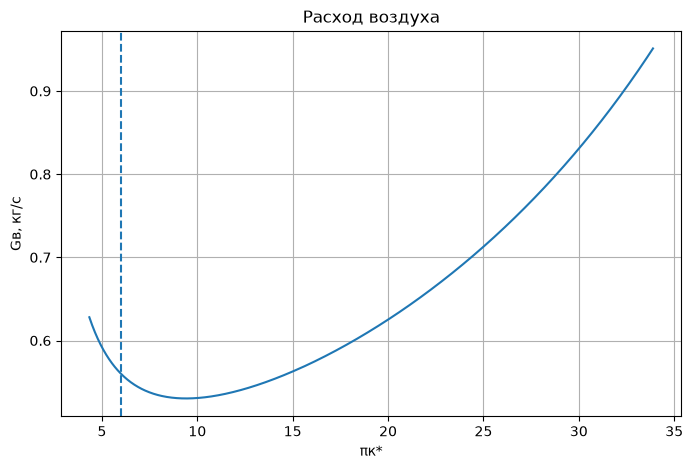

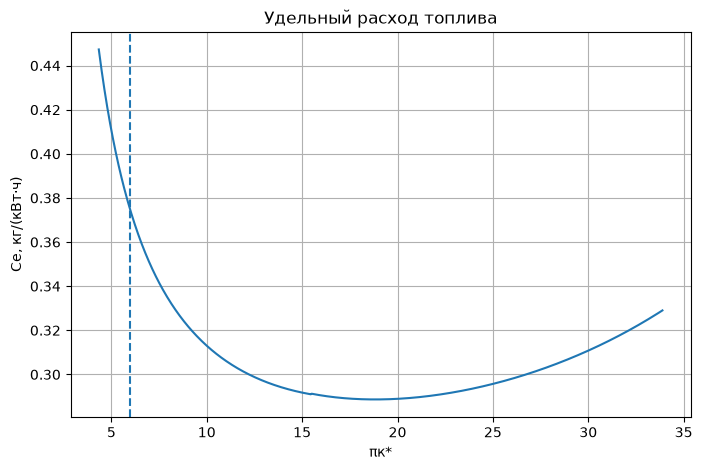

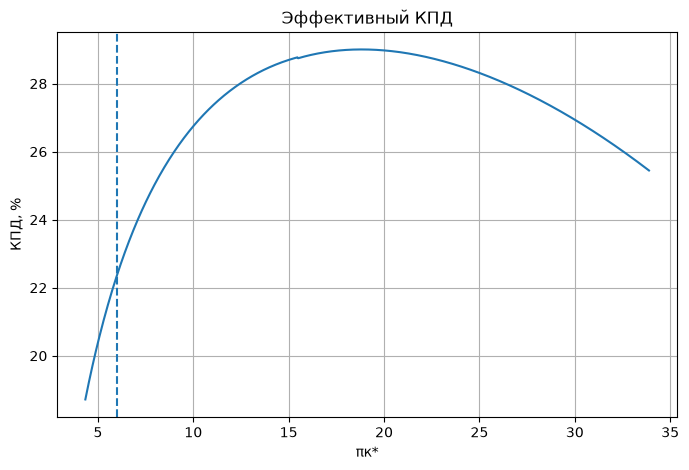

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['G_air'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Gв, кг/с')
plt.title('Расход воздуха')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['Ce_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Ce, кг/(кВт·ч)')
plt.title('Удельный расход топлива')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], 100*variants['eta_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('КПД, %')
plt.title('Эффективный КПД')
plt.grid()
plt.show()